In [72]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt
import numpy as np
import random

### 이진 분류 실습 문제 1

## Iris Dataset
: 붓꽃의 꽃받침과 꽃잎의 측정값을 이용해 Setosa와 Versicolor 두 품종을 구분하는 이진 분류 모델 구현.

- 전체 데이터: 150개
- 이번 실습에서 사용할 데이터: 100개
- 입력 특징: 4개
- 정답: 꽃 품종 (Setosa 또는 Versicolor)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `sepal_length` | 꽃받침 길이 | 꽃받침의 길이, cm |
| `sepal_width` | 꽃받침 너비 | 꽃받침의 너비, cm |
| `petal_length` | 꽃잎 길이 | 꽃잎의 길이, cm |
| `petal_width` | 꽃잎 너비 | 꽃잎의 너비, cm |
| `species` | 꽃 품종 | `setosa`, `versicolor`, `virginica` |


#### Step1. 데이터 불러오기 및 전처리

**실습 조건**
- `setosa`와 `versicolor` 두 품종만 사용하고 `virginica`는 제외한다.
- `setosa`는 클래스 0, `versicolor`는 클래스 1로 변환한다.
- 4개의 측정값을 입력값(X), 품종 레이블을 정답(y)으로 사용한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 학습 데이터의 평균과 표준편차를 이용해 입력 특징을 표준화한다.

In [73]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
columns = ['sepal_length',
            'sepal_width',
            'petal_length',
            'petal_width',
            'species'
            ]

df = pd.read_csv(url)

# Setosa와 Versicolor만 선택
df = df[df["species"].isin(["setosa", "versicolor"])].copy()

# df["species"] = (df["species"]=='versicolor').astype(int)
y_value = df['species'].map({'setosa':0, 'versicolor':1}).values

X = torch.tensor(df[['sepal_length',
            'sepal_width',
            'petal_length',
            'petal_width']].values, dtype = torch.float32)
y = torch.tensor(y_value, dtype = torch.float32).reshape(-1,1)

torch.manual_seed(42)
train_indices=[]
test_indices=[]

for y_value in [0,1]:
    y_indices = torch.where(y.squeeze() == y_value)[0]

    y_indices = y_indices[torch.randperm(len(y_indices))]

    split = int(len(y_indices)* 0.8)

    train_indices.extend(y_indices[:split])
    test_indices.extend(y_indices[split:])

train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train.mean(dim=0)
std = X_train.std(dim=0). clamp(min=1e-8)

X_train = (X_train - mean)/std
X_test = (X_test- mean)/std

In [74]:
'''
데이터 값이(10개) 작아서 생략
BATCH_SIZE = 32

train_DS = TensorDataset(X_train, y_train)
test_DS = TensorDataset(X_test, y_test)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False)

N = len(train_DL.dataset)
'''

'\n데이터 값이(10개) 작아서 생략\nBATCH_SIZE = 32\n\ntrain_DS = TensorDataset(X_train, y_train)\ntest_DS = TensorDataset(X_test, y_test)\n\ntrain_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)\ntest_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False)\n\nN = len(train_DL.dataset)\n'

#### Step2. 모델 만들기

**목표:** Banknote Authentication 실습에서 사용한 MLP 구조로 붓꽃 품종을 분류한다.

- 입력 노드: 4개
- 은닉층: 100개 노드
- 출력 노드: 1개
- 출력 활성화 함수: Sigmoid
- 예측값이 0.5 이상이면 클래스 1, 0.5 미만이면 클래스 0

In [75]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )

    def forward(self, x):
        x = self.linear(x)
        return x

model = MLP()

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: BCELoss
- 학습률(LR): 0.1
- Epoch: 100
- Batch size: 16 또는 32

In [76]:

LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history=[]

model.train()
for ep in range(EPOCH):
    rloss = 0
    
    for x_batch, y_batch in train_DL:

        y_hat = model(x_batch)

        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    epoch_loss = rloss/N
    loss_history. append(epoch_loss)


#### Step4. 모델 테스트하기

- Sigmoid 출력값에 임계값 0.5를 적용해 클래스를 예측.
- 전체 테스트 데이터 중 정답을 맞힌 개수와 Accuracy(%)를 출력.

In [77]:
model.eval()

correct =0
total = 0
with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)
        pred = (y_hat >= 0.5).float()

        correct += (pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct/total*100


#### Step5. 테스트 결과 시각화

- 실제 클래스와 예측 클래스를 이용해 2×2 혼동행렬(Confusion Matrix)을 작성.
- 실제 클래스별 예측 확률 분포를 히스토그램으로 나타내시오.
- 혼동행렬의 행은 실제 클래스, 열은 예측 클래스로 표시하시오.
- 클래스 0과 클래스 1이 무엇을 의미하는지 그래프에 표시하시오.

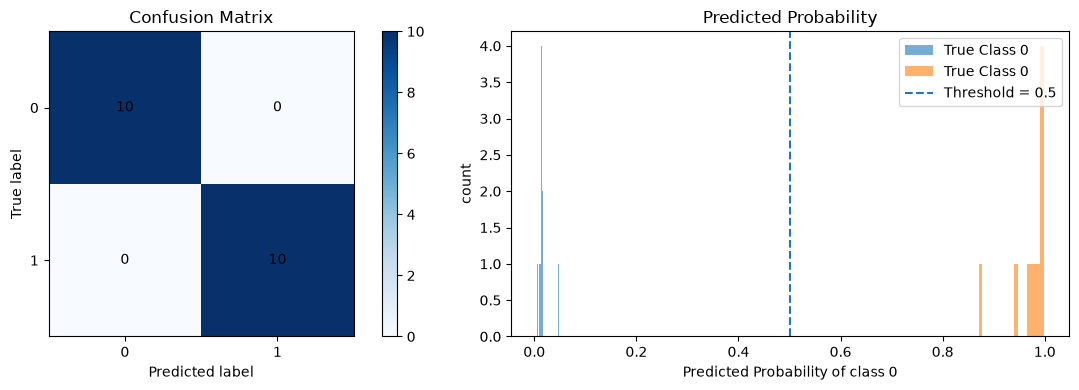

In [81]:
model.eval()

y_true_all = []
y_prob_all =[]

with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)

        y_true_all.append(y_batch.numpy().reshape(-1))
        y_prob_all.append(y_hat.numpy().reshape(-1))

y_true = np.concatenate(y_true_all).astype(int)
y_prob = np.concatenate(y_prob_all)
y_pred = (y_prob >=0.5).astype(int)

cm = np.zeros((2,2), dtype=int)
for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

fig, axes = plt.subplots(1,2,figsize = (12,4))

im = axes[0].imshow(cm, cmap = 'Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_xticks([0,1], labels=['0','1'])
axes[0].set_yticks([0,1], labels=['0','1'])

for i in range(2):
    for j in range(2):
        axes[0].text(j,i, cm[i,j], ha = 'center', va = 'center')

fig.colorbar(im, ax = axes[0])

axes[1].hist(y_prob[y_true == 0], bins = 20, alpha = 0.6, label='True Class 0')
axes[1].hist(y_prob[y_true == 1], bins = 20, alpha = 0.6, label='True Class 0')
axes[1].axvline(0.5, linestyle = '--', label='Threshold = 0.5')
axes[1].set_title('Predicted Probability')
axes[1].set_xlabel('Predicted Probability of class 0')
axes[1].set_ylabel('count')
axes[1].legend()

plt.tight_layout()
plt.show()

#### STEP 6. 파라미터 개수 확인

In [79]:
total_param = sum(p.numel() for p in model.parameters())
print(total_param)

601
